---

<table style="width:100%">
  <tr>
    <th>
        <div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> Конспект лекцій з предмету: </p>
<p style="text-align: center;"><b><h2>"Схемотехніка радіотехнічних пристроїв. Частина 1"</h2></b></p>
<p style="text-align: center;"><b><h3>Тема 4. Каскади СС, СБ, СЗ. Корекція АЧХ</h3></b></p>
<p style="text-align: center;"> Національний університет "Чернігівська політехніка"</p>
<hr/>
<p style="text-align: center;"><b>Питання теми:</b></p>
<ul style="text-align: left;">
  <li>1.16. Каскад за схемою зі спільним стоком. Основні параметри і співвідношення. Кола зміщення та стабілізації</li>
  <li>1.17. Каскади зі спільною базою та зі спільним затвором. Основні параметри і співвідношення</li>
  <li>1.18. Корекція амплітудно-частотної характеристики підсилювача з боку витоку транзистора</li>
  <li>1.19. Корекція амплітудно-частотної характеристики підсилювача з боку стоку транзистора</li>
</ul>
</div>
    </th>
    <th>
<div style="text-align: center; background-color: #f0f0f0; padding: 20px; border-radius: 10px;">
<p style="text-align: center;"> <b>Викладач:</b> </p>
<p style="text-align: center;"> Доктор філософії</p>
<p style="text-align: center;"> Пахалюк Богдан Петрович</p>
<hr/>
<p style="text-align: center; font-size: 0.9em;">Тема 4 з 14</p>
</div>
    </th>
  </tr>
</table>

---


---

<p style="text-align: center;"><b>Зміст</b></p>

* [Каскад зі спільним стоком (витоковий повторювач)](#cd-stage)
    * [🔬 Інтерактивно: витоковий повторювач: коефіцієнт передачі і вихідний опір (PySpice)](#cd-interactive)
* [Каскади зі спільною базою та зі спільним затвором](#cb-stage)
    * [🔬 Інтерактивно: порівняння АЧХ каскадів СЕ і СБ (PySpice)](#cb-ce-interactive)
* [Корекція АЧХ з боку витоку (емітера)](#source-corr)
    * [🔬 Інтерактивно: витокова корекція АЧХ (PySpice)](#source-corr-interactive)
* [Корекція АЧХ з боку стоку (колектора)](#drain-corr)
    * [🔬 Інтерактивно: індуктивна ВЧ-корекція: АЧХ і перехідна характеристика (PySpice)](#drain-corr-interactive)
* [📌 Підсумок теми](#topic-summary)
* [📚 Рекомендована література та ресурси](#references)

> 💡 Код демонстрацій та інтерактивних графіків **згорнуто**, щоб не відволікати від матеріалу. Щоб переглянути його, натисніть на «⋯» (або на смужку ліворуч від комірки). Для роботи інтерактивних елементів виконайте всі комірки: *Run → Run All Cells*.

---

**Підключення бібліотек.** NumPy/SciPy/Matplotlib — чисельні розрахунки та графіки, SymPy — символьні обчислення, ipywidgets — інтерактивні повзунки, PySpice + ngspice — моделювання схем (ОП μA741, таймер 555 та транзистори описано SPICE-моделями з теки `spice/`), schemdraw — побудова схем з умовними позначеннями за ДСТУ. Цю комірку потрібно виконати першою; у Google Colab вона спершу встановлює ngspice і бібліотеки (близько хвилини).

In [1]:
import sys, os
if 'google.colab' in sys.modules and not os.path.exists('/usr/lib/x86_64-linux-gnu/libngspice.so'):   # Google Colab: ngspice та бібліотеки (~1 хв)
    !apt-get -qq install -y ngspice libngspice0-dev > /dev/null
    %pip install -q PySpice==1.5 schemdraw==0.23 engineering_notation==0.13.3

# SPICE-моделі компонентів (ОП μA741, таймер 555, діоди, транзистори) лежать у теці spice/;
# якщо зошит відкрито окремо (напр. у Colab), завантажуємо їх із репозиторію
SPICE_DIR = 'spice'
if not os.path.isdir(SPICE_DIR):
    import urllib.request
    os.makedirs(SPICE_DIR, exist_ok=True)
    _repo = 'https://raw.githubusercontent.com/vim4all/Lectures_Schematics_of_radio_technical-devices_in_Ukrainian/main/spice/'
    for _f in ['uA741.lib', 'BIP-555.lib', '1N4007.mod', '2n2222a.lib', '2n3904.lib']:
        urllib.request.urlretrieve(_repo + _f, os.path.join(SPICE_DIR, _f))
def spice_model(name):
    return os.path.abspath(os.path.join(SPICE_DIR, name))

import warnings
warnings.filterwarnings('ignore', message='Unable to import Axes3D')
import sympy as smp
from sympy import symbols, Matrix, simplify, factor, solve, Eq, latex
import matplotlib.pyplot as plt
import numpy as np
from scipy import signal
from ipywidgets import interact, interactive, fixed, HBox, VBox, Output
import ipywidgets as widgets
from IPython.display import display, HTML, Markdown
%matplotlib inline
try:                                     # схеми й графіки — лише PNG (менший розмір зошитів)
    get_ipython().display_formatter.formatters['image/svg+xml'].enabled = False
except Exception:
    pass

import math
from engineering_notation import EngNumber

import PySpice.Logging.Logging as Logging
logger = Logging.setup_logging(logging_level='ERROR')
from PySpice.Spice.Netlist import Circuit
from PySpice.Unit import *

# ngspice ≥ 41 пише в stderr інформаційні повідомлення (напр. "Using SPARSE 1.3 as Direct Linear Solver"),
# які PySpice 1.5 вважає помилкою симуляції. Сприймаємо як помилку лише рядки, що містять "error".
from PySpice.Spice.NgSpice import Shared as _ngspice_shared
_orig_send_char = _ngspice_shared.NgSpiceShared._send_char
def _send_char(message_c, ngspice_id, user_data):
    message = _ngspice_shared.ffi_string_utf8(message_c)
    prefix, _, content = message.partition(' ')
    if prefix == 'stderr' and 'error' not in content.lower() and 'init file' not in content:
        self = _ngspice_shared.ffi.from_handle(user_data)
        self._stderr.append(content)
        return self.send_char(message, ngspice_id)
    return _orig_send_char(message_c, ngspice_id, user_data)
_ngspice_shared.NgSpiceShared._send_char = staticmethod(_send_char)

def opamp_circuit(title, supply=15):
    """Схема з ОП μA741 і двополярним живленням ±supply (вузли vcc, vee)."""
    c = Circuit(title)
    c.include(spice_model('uA741.lib'))
    c.V('cc', 'vcc', c.gnd, supply)
    c.V('ee', 'vee', c.gnd, -supply)
    return c

def add_opamp(c, name, plus, minus, out):
    """ОП μA741: X<name> (+) (−) Vcc Vee вихід."""
    c.X(name, 'UA741', plus, minus, 'vcc', 'vee', out)

def tran(c, step, stop, start=0, **kw):
    """Перехідний аналіз: повертає (t, словник напруг вузлів у вигляді numpy-масивів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).transient(step_time=step, end_time=stop, start_time=start, **kw)
    return np.array(a.time), {str(k): np.array(v) for k, v in a.nodes.items()}

def ac(c, f_start=1, f_stop=10e6, points=40):
    """AC-аналіз: повертає (f, словник комплексних напруг вузлів)."""
    a = c.simulator(temperature=25, nominal_temperature=25).ac(start_frequency=f_start, stop_frequency=f_stop,
                                                                 number_of_points=points, variation='dec')
    return np.array(a.frequency), {str(k): np.array(v) for k, v in a.nodes.items()}

def db(x):
    return 20 * np.log10(np.maximum(np.abs(x), 1e-12))

try:
    import schemdraw
    import schemdraw.elements as elm
    SCHEMDRAW_AVAILABLE = True
except ImportError:
    SCHEMDRAW_AVAILABLE = False
    print('schemdraw не встановлено (pip install schemdraw)')

plt.rcParams.update({
    'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.3,
    'axes.labelsize': 12, 'axes.titlesize': 13, 'lines.linewidth': 2,
    'font.size': 11,
})

if SCHEMDRAW_AVAILABLE:
    # Умовні позначення за ДСТУ/IEC: резистор — прямокутник, джерело ЕРС — коло зі стрілкою,
    # операційний підсилювач — прямокутник із символом ▷∞, логічні елементи — прямокутники з «&», «1»
    from schemdraw.segments import Segment, SegmentCircle, SegmentText
    elm.style(elm.STYLE_IEC)
    schemdraw.use('matplotlib')
    import schemdraw.backends.svgtext as _svgtext       # оцінювач розміру тексту schemdraw не сприймає символ «&»
    _orig_text_size = _svgtext.text_approx_size
    _svgtext.text_approx_size = lambda text, *a, **k: _orig_text_size(text.replace('&', '8'), *a, **k)

    class EMF(elm.Source):
        """Джерело ЕРС: стрілка всередині кола вказує напрямок дії ЕРС."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.2, 0), (.8, 0)], arrow='->', arrowwidth=.16, arrowlength=.25))

    class CurrentSource(elm.Source):
        """Джерело струму: подвійна стрілка вказує напрямок струму."""
        def __init__(self, **kwargs):
            super().__init__(**kwargs)
            self.segments.append(Segment([(.15, 0), (.85, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))
            self.segments.append(Segment([(.15, 0), (.62, 0)], arrow='->', arrowwidth=.16, arrowlength=.2))

    class OpAmp(elm.Element):
        """Операційний підсилювач за ДСТУ: прямокутник із символом ▷∞.
        Інвертувальний вхід in1 (з кружечком інверсії) — угорі, неінвертувальний in2 — унизу;
        swap=True міняє входи місцями (неінвертувальний — угорі). Виводи: in1, in2, out, vd (живлення +), vs (живлення −)."""
        def __init__(self, swap=False, signs=True, **kwargs):
            super().__init__(**kwargs)
            w, h, lead, r = 2.0, 2.6, 0.6, 0.12
            yi, yn = (0.65, -0.65) if not swap else (-0.65, 0.65)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(Segment([(0.55, h/2 - 0.3), (0.55, h/2 - 0.8), (0.95, h/2 - 0.55), (0.55, h/2 - 0.3)]))
            self.segments.append(SegmentText((1.35, h/2 - 0.55), '∞', fontsize=14))
            self.segments.append(SegmentCircle((-r, yi), r))
            self.segments.append(Segment([(-lead, yi), (-2*r, yi)]))
            self.segments.append(Segment([(-lead, yn), (0, yn)]))
            self.segments.append(Segment([(w, 0), (w + lead, 0)]))
            if signs:
                self.segments.append(SegmentText((0.25, yi), '−', fontsize=12))
                self.segments.append(SegmentText((0.25, yn), '+', fontsize=12))
            self.anchors.update({'in1': (-lead, yi), 'in2': (-lead, yn), 'out': (w + lead, 0),
                                 'vd': (w/2, h/2), 'vs': (w/2, -h/2), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

    class Gate(elm.Element):
        """Логічний елемент за ДСТУ: прямокутник із функцією ('&', '1', '=1') і кружечком інверсії на виході.
        Виводи: in1 … inN (зверху вниз), out."""
        def __init__(self, func='&', inputs=2, inv=True, **kwargs):
            super().__init__(**kwargs)
            w, lead, r = 1.4, 0.5, 0.12
            h = max(1.4, 0.8 * inputs)
            self.segments.append(Segment([(0, h/2), (w, h/2), (w, -h/2), (0, -h/2), (0, h/2)]))
            self.segments.append(SegmentText((w/2, h/2 - 0.3), func, fontsize=13))
            ys = [0.0] if inputs == 1 else list(np.linspace(h/2 - 0.4, -h/2 + 0.4, inputs))
            for k, y in enumerate(ys):
                self.segments.append(Segment([(-lead, y), (0, y)]))
                self.anchors[f'in{k+1}'] = (-lead, y)
            x0 = w
            if inv:
                self.segments.append(SegmentCircle((w + r, 0), r))
                x0 = w + 2*r
            self.segments.append(Segment([(x0, 0), (w + lead, 0)]))
            self.anchors.update({'out': (w + lead, 0), 'center': (w/2, 0)})
            self.elmparams['drop'] = (w + lead, 0)
            self.theta(0)            # не успадковувати напрямок попереднього елемента

---

## Каскад зі спільним стоком (витоковий повторювач) <a class="anchor" id="cd-stage"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.16</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати роботу витокового повторювача та його відмінності від емітерного
> - Розраховувати $K_u$, $R_{вх}$, $R_{вих}$ каскаду СС
> - Вибирати коло зміщення для каскаду СС і підвищувати його вхідний опір

</div>

Навантаження ввімкнено в коло витоку, стік з'єднано з джерелом живлення. Як і емітерний повторювач, каскад СС має **100 % послідовний НЗЗ за напругою**, не інвертує сигнал і має $K_u < 1$. Головна перевага — **надзвичайно великий вхідний опір** (затвор не споживає струму), тому витоковий повторювач — типовий вхідний буфер для високоомних джерел: щупи осцилографів, п'єзо- та ємнісні датчики, електретні мікрофони.

### Основні співвідношення

Позначимо $R'_в = R_в\parallel R_н$, $S$ — крутизна в робочій точці.
$$K_u = \frac{SR'_в}{1 + SR'_в},\qquad R_{вих} = R_в\parallel\frac{1}{S}\approx\frac1S,\qquad R_{вх} = R_з\;(\text{або } R_{з1}\parallel R_{з2}).$$
Оскільки $S$ польового транзистора невелика (1…10 мА/В), коефіцієнт передачі помітно менший від одиниці (0,6…0,9), а вихідний опір — сотні ом (у емітерного повторювача — одиниці–десятки ом). Тому часто після витокового повторювача ставлять емітерний (складовий повторювач, тема 5).

### Кола зміщення і стабілізації

- **Автоматичне зміщення з відводом:** резистор у витоку розділено на $R_{в1}$ (задає $U_{зв0} = -I_{с0}R_{в1}$) і $R_{в2}$; затвор через $R_з$ підключено до точки між ними. Так одночасно забезпечується мала $|U_{зв0}|$ і великий опір $R_в = R_{в1} + R_{в2}$ для глибокого НЗЗ.
- **Дільник у колі затвора** (для МДН з індукованим каналом) — напругу затвора вибирають ≈ $E_ж/2$ для симетричного розмаху.
- **Стабілізація** — сам 100 % НЗЗ: будь-яка зміна струму стоку змінює напругу на $R_в$ і протидіє цій зміні.

**Вольтодобавка (bootstrap).** Якщо $R_з$ підключено до відводу між $R_{в1}$ і $R_{в2}$, то змінна напруга на ньому дорівнює $u_{вх}(1 - K'_u)$, де $K'_u$ — коефіцієнт передачі до відводу, і ефективний вхідний опір зростає:
$$R_{вх} = \frac{R_з}{1 - K'_u},$$
досягаючи сотень мегаом.

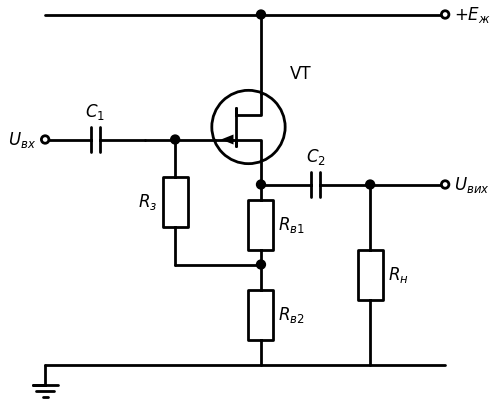

In [2]:
# Витоковий повторювач з автоматичним зміщенням і вольтодобавкою (R_з — до відводу між R_в1 і R_в2)
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (8, 7)); d += elm.Dot(open=True).at((8, 7)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 4.5)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 4.5)).to((2, 4.5)).label('$C_1$')
        d += W((2, 4.5), (3.4, 4.5)); d += elm.Dot().at((2.6, 4.5))
        d += (q := elm.JFetN(circle=True).theta(0).reverse().at((3.4, 4.5)).anchor('gate'))
        d += elm.Label().at((q.drain[0] + 0.7, q.drain[1] + 0.3)).label('VT')
        d += W(q.drain, (q.drain[0], 7)); d += elm.Dot().at((q.drain[0], 7))
        d += W(q.source, (q.source[0], 3.6)); d += elm.Dot().at((q.source[0], 3.6))
        d += elm.Resistor().at((q.source[0], 3.6)).to((q.source[0], 2.0)).label('$R_{в1}$', loc='bottom')
        d += elm.Dot().at((q.source[0], 2.0))
        d += elm.Resistor().at((q.source[0], 2.0)).to((q.source[0], 0)).label('$R_{в2}$', loc='bottom')
        d += elm.Resistor().at((2.6, 4.5)).to((2.6, 2.0)).label('$R_з$', loc='top'); d += W((2.6, 2.0), (q.source[0], 2.0))
        d += elm.Capacitor().at((q.source[0], 3.6)).to((6.5, 3.6)).label('$C_2$')
        d += elm.Dot().at((6.5, 3.6)); d += W((6.5, 3.6), (8, 3.6)); d += elm.Dot(open=True).at((8, 3.6)).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((6.5, 3.6)).to((6.5, 0)).label('$R_н$', loc='bottom')

---
### 🔬 Інтерактивно: витоковий повторювач: коефіцієнт передачі і вихідний опір (PySpice) <a class="anchor" id="cd-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Повторювач на ПТ ($I_{с.поч} = 4$ мА, $U_{відс} = -2$ В), $E_ж = 15$ В, $R_{в1} = 680$ Ом, $R_{в2}$ — змінний. Зменшуйте опір навантаження: коефіцієнт передачі падає, бо вихідний опір $\approx 1/S$ утворює з $R_н$ подільник. Під графіком — порівняння з формулою $K_u = SR'_в/(1+SR'_в)$.

</div>

In [3]:
# Витоковий повторювач (PySpice): часові діаграми та коефіцієнт передачі
def cd_stage(Rs2_k=4.7, Rl_k=10.0):
    c = Circuit('Source follower')
    c.model('JN', 'NJF', VTO=-2.0, BETA=1e-3, LAMBDA=5e-3, CGS=4e-12, CGD=2e-12)   # ПТ: I_с.поч = 4 мА, U_відс = −2 В
    c.V('dd', 'vdd', c.gnd, 15)
    c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1.0, frequency=1e3)
    c.C(1, 'src', 'g', 1e-6); c.R('g', 'g', 'tap', 1e6)
    c.JFET(1, 'vdd', 'g', 's', model='JN')
    c.R('s1', 's', 'tap', 680); c.R('s2', 'tap', c.gnd, Rs2_k * 1e3)
    c.C(2, 's', 'out', 100e-6); c.R('L', 'out', c.gnd, Rl_k * 1e3)
    op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
    us, ut = float(np.array(op['s'])[0]), float(np.array(op['tap'])[0])
    Id = (us - ut) / 680
    t, v = tran(c, 2e-6, 0.3, start=0.297)
    tt = (t - t[0]) * 1e3
    fig, ax = plt.subplots(figsize=(9, 3.8))
    ax.plot(tt, v['src'], 'k--', lw=1, label='$u_{вх}$'); ax.plot(tt, v['out'], color='#F44336', label='$u_{вих}$')
    ax.set_xlabel('t, мс'); ax.set_ylabel('В'); ax.legend(loc='upper right')
    ax.set_title(f'$I_{{с0}}$ = {Id*1e3:.2f} мА,  $U_{{в}}$ = {us:.2f} В')
    plt.tight_layout(); plt.show()
    S = 2 * np.sqrt(4e-3 * Id) / 2.0
    Rp = 1 / (1 / (680 + Rs2_k * 1e3) + 1 / (Rl_k * 1e3))
    print(f'S = {S*1e3:.2f} мА/В;  R_вих ≈ 1/S = {1/S:.0f} Ом;  K_u: формула {S*Rp/(1+S*Rp):.3f},  PySpice {v["out"].max():.3f}')

interact(cd_stage,
         Rs2_k=widgets.FloatSlider(min=1, max=20, step=0.1, value=4.7, description='Rв2 (кОм)'),
         Rl_k=widgets.FloatLogSlider(base=10, min=-1, max=2, step=0.1, value=10, description='Rн (кОм)'));

interactive(children=(FloatSlider(value=4.7, description='Rв2 (кОм)', max=20.0, min=1.0), FloatLogSlider(value…

---

## Каскади зі спільною базою та зі спільним затвором <a class="anchor" id="cb-stage"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.17</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати, чому каскад СБ (СЗ) має малий вхідний і великий вихідний опір
> - Розраховувати $K_u$, $K_i$, $R_{вх}$, $R_{вих}$ каскадів СБ і СЗ
> - Пояснювати перевагу каскаду СБ на високих частотах (відсутність ефекту Міллера)

</div>

У каскаді **СБ** вхідний сигнал подається в емітер, база заземлена за змінним струмом (конденсатором $C_б$), вихід — з колектора. Каскад **СЗ** — його аналог на польовому транзисторі (сигнал у витік, затвор заземлено).

### Основні співвідношення каскаду СБ
$$K_i = \alpha = \frac{\beta}{1+\beta} \lesssim 1,\qquad K_u = g_m\,(R_к\parallel R_н) \;(\text{без інверсії}),$$
$$R_{вх} = R_е\parallel\left(r_е + \frac{r_б}{1+\beta}\right) \approx r_е = \frac{\varphi_т}{I_{е0}}\;(\text{одиниці–десятки ом}),\qquad R_{вих} \approx R_к\;(\text{вихідний опір транзистора — мегаоми}).$$

### Каскад СЗ
$$K_u = S\,(R_с\parallel R_н),\qquad R_{вх} = R_в\parallel\frac{1}{S},\qquad R_{вих} \approx R_с .$$

### Властивості і застосування

- **Малий вхідний опір** — каскад «навантажує» джерело. Через це від джерела напруги з опором $R_c$ наскрізне підсилення $\approx R_к/(R_c + r_е)$ значно менше, ніж у СЕ. Зате вхід СБ — майже ідеальний **приймач струму**, а вихід — **джерело струму** (повторювач струму).
- **Широка смуга пропускання.** Ємність колекторного переходу $C_к$ не з'єднує вихід із входом (база заземлена), тому **немає ефекту Міллера**, через який у каскаді СЕ ємність $C_к$ на вході множиться на $(1 + |K_u|)$. Гранична частота каскаду СБ — $f_\alpha \approx f_т$, тоді як у СЕ — $f_\beta = f_т/\beta$.
- **Застосування:** підсилювачі ВЧ і НВЧ (особливо з низькоомними фідерами 50/75 Ом — вхідний опір легко узгодити), **каскодні схеми** (тема 5), підсилювачі з високою лінійністю, струмові дзеркала і схеми зі струмовим виходом.

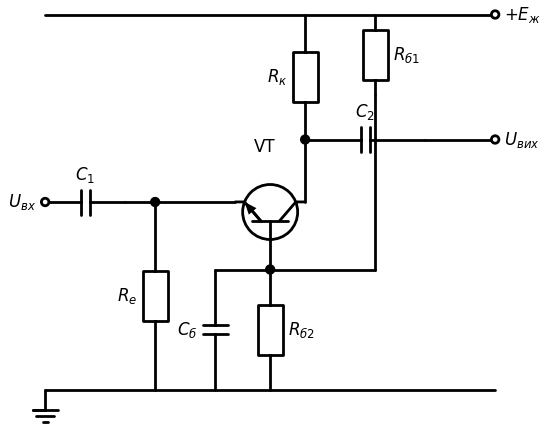

In [4]:
# Каскад СБ: база заземлена за змінним струмом конденсатором C_б
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7.5), (9, 7.5)); d += elm.Dot(open=True).at((9, 7.5)).label('$+E_ж$', loc='right')
        d += W((0, 0), (9, 0)); d += elm.Ground().at((0, 0))
        d += elm.BjtNpn(circle=True).theta(90).flip().at((4.5, 3.0)).anchor('base')   # емітер ліворуч, колектор праворуч
        d += elm.Label().at((4.5, 4.75)).label('VT')
        d += elm.Dot(open=True).at((0, 3.75)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 3.75)).to((1.6, 3.75)).label('$C_1$')
        d += W((1.6, 3.75), (3.8, 3.75)); d += elm.Dot().at((2.2, 3.75))
        d += elm.Resistor().at((2.2, 3.75)).to((2.2, 0)).label('$R_е$', loc='top')
        d += W((4.5, 3.0), (4.5, 2.4)); d += elm.Dot().at((4.5, 2.4))
        d += elm.Resistor().at((4.5, 2.4)).to((4.5, 0)).label('$R_{б2}$', loc='bottom')
        d += W((4.5, 2.4), (3.4, 2.4)); d += elm.Capacitor().at((3.4, 2.4)).to((3.4, 0)).label('$C_б$', loc='top')
        d += W((4.5, 2.4), (6.6, 2.4)); d += W((6.6, 2.4), (6.6, 5.9))
        d += elm.Resistor().at((6.6, 7.5)).to((6.6, 5.9)).label('$R_{б1}$', loc='bottom')
        d += W((5.2, 3.75), (5.2, 5.0)); d += elm.Dot().at((5.2, 5.0))
        d += elm.Resistor().at((5.2, 7.5)).to((5.2, 5.0)).label('$R_к$', loc='top')
        d += elm.Capacitor().at((5.2, 5.0)).to((7.6, 5.0)).label('$C_2$')
        d += W((7.6, 5.0), (9, 5.0)); d += elm.Dot(open=True).at((9, 5.0)).label('$U_{вих}$', loc='right')

---
### 🔬 Інтерактивно: порівняння АЧХ каскадів СЕ і СБ (PySpice) <a class="anchor" id="cb-ce-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Два каскади на 2N3904 з однаковим режимом ($I_{к0} \approx 1{,}4$ мА, $R_к = 4{,}7$ кОм) працюють від джерела з опором $R_c$ на ємнісне навантаження $C_н$. Каскад СЕ має більше підсилення, але верхня гранична частота каскаду СБ — у кілька разів вища (тим більше, чим більший $R_c$; при великій $C_н$ обидва каскади обмежує полюс навантаження $R_кC_н$): у СЕ ємність колекторного переходу, помножена на $(1+|K_u|)$ (ефект Міллера), разом з $R_c$ утворює низькочастотний полюс.

</div>

In [5]:
# Каскади СЕ і СБ: AC-аналіз
def cb_vs_ce(Rs=200.0, Cl_pF=1.0):
    res = {}
    for kind in ('СЕ', 'СБ'):
        c = Circuit(kind)
        c.include(spice_model('2n3904.lib'))
        c.V('cc', 'vcc', c.gnd, 12)
        c.SinusoidalVoltageSource('in', 'src', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.R('s', 'src', 'sx', Rs)
        c.R('b1', 'vcc', 'b', 47e3); c.R('b2', 'b', c.gnd, 10e3)
        c.R('c', 'vcc', 'out', 4.7e3); c.R('e', 'e', c.gnd, 1e3); c.C('L', 'out', c.gnd, Cl_pF * 1e-12)
        c.BJT(1, 'out', 'b', 'e', model='Q2N3904')
        if kind == 'СЕ':
            c.C(1, 'sx', 'b', 10e-6); c.C('e', 'e', c.gnd, 100e-6)
        else:
            c.C('b', 'b', c.gnd, 100e-6); c.C(1, 'sx', 'e', 100e-6)
        f, v = ac(c, 1e3, 1e10, 30)
        res[kind] = (f, np.abs(v['out']))
    fig, ax = plt.subplots(figsize=(9, 4))
    for kind, col in (('СЕ', '#2196F3'), ('СБ', '#F44336')):
        f, g = res[kind]; g0 = g[np.argmin(abs(f - 1e5))]
        fv = f[np.argmax((g < g0 / np.sqrt(2)) & (f > 1e5))]
        ax.semilogx(f, db(g), color=col, label=f'{kind}: K = {g0:.0f}, fв = {fv/1e6:.2f} МГц')
        ax.axvline(fv, color=col, ls=':', lw=1)
    ax.set_xlabel('Частота, Гц'); ax.set_ylabel('Наскрізний K, дБ'); ax.set_ylim(-20, 55); ax.legend()
    ax.set_title(f'Опір джерела $R_c$ = {Rs:.0f} Ом, $C_н$ = {Cl_pF:.0f} пФ')
    plt.tight_layout(); plt.show()

interact(cb_vs_ce,
         Rs=widgets.FloatLogSlider(base=10, min=1, max=3.5, step=0.1, value=200, description='Rc (Ом)'),
         Cl_pF=widgets.FloatSlider(min=0.5, max=50, step=0.5, value=1, description='Cн (пФ)'));

interactive(children=(FloatLogSlider(value=200.0, description='Rc (Ом)', max=3.5, min=1.0), FloatSlider(value=…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Каскад СБ не «гірший» за СЕ, хоча $K_i < 1$.** Підсилення за напругою в нього таке саме, як у СЕ ($g_m R_к$), якщо джерело сигналу низькоомне. Малий $R_{вх}$ — це не недолік, а властивість: каскад СБ ідеально сприймає струмовий сигнал (наприклад, від колектора іншого транзистора в каскоді) і узгоджується з 50-омними лініями.

</div>

---

## Корекція АЧХ з боку витоку (емітера) <a class="anchor" id="source-corr"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.18</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати принцип високочастотної корекції частотно-залежним НЗЗ у колі витоку
> - Вибирати коригувальну ємність з умови компенсації полюса навантаження
> - Оцінювати розширення смуги та втрату підсилення

</div>

**Задача корекції АЧХ** — розширити смугу пропускання (або вирівняти АЧХ) без зміни підсилювального елемента. На верхніх частотах АЧХ каскаду СВ спадає через ємність навантаження $C_0$ (вхідна ємність наступного каскаду + монтаж + вихідна ємність ПТ), яка шунтує $R_с$:
$$K(j\omega) = -\frac{SR_с}{1 + j\omega\tau_в},\qquad \tau_в = R_сC_0 .$$

**Витокова (емітерна) високочастотна корекція.** Резистор $R_в$ у колі витоку залишають **незашунтованим** — він створює НЗЗ за струмом, який зменшує підсилення в $F = 1 + SR_в$ разів. Паралельно $R_в$ вмикають **невелику** коригувальну ємність $C_к$. На низьких і середніх частотах вона не діє, а на верхніх її опір зменшується, НЗЗ слабшає і підсилення **піднімається**, компенсуючи спад через $C_0$:
$$K(j\omega) = -\frac{SR_с}{1 + j\omega\tau_в}\cdot\frac{1 + j\omega R_вC_к}{(1 + SR_в) + j\omega R_вC_к}.$$
Якщо вибрати
$$R_вC_к = \tau_в = R_сC_0,$$
нуль коригувального кола компенсує полюс навантаження, і
$$K(j\omega) = -\frac{SR_с}{1 + SR_в}\cdot\frac{1}{1 + j\omega\tau_в/(1 + SR_в)}:$$
підсилення зменшилося в $F = 1 + SR_в$ разів, а верхня гранична частота **зросла в $F$ разів** — площа підсилення не змінилася, але смугу перерозподілено. При $R_вC_к > \tau_в$ на АЧХ з'являється підйом (перекорекція), при $R_вC_к < \tau_в$ — недокорекція.

Такий самий метод застосовують у каскадах СЕ (емітерна корекція: $R_е$ з малою $C_е$). Перевага — простота, відсутність котушок; недолік — втрата підсилення.

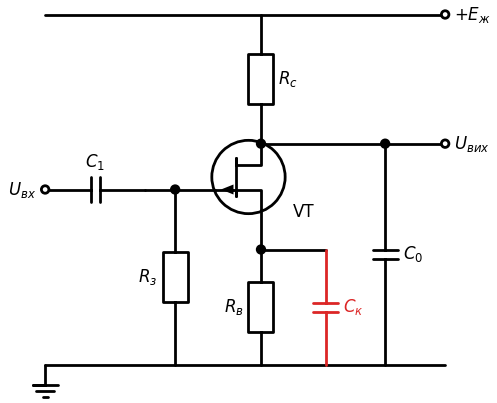

In [6]:
# Каскад СВ з витоковою ВЧ-корекцією: R_в незашунтовано, паралельно — мала C_к; C_0 — ємність навантаження
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 7), (8, 7)); d += elm.Dot(open=True).at((8, 7)).label('$+E_ж$', loc='right')
        d += W((0, 0), (8, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 3.5)).label('$U_{вх}$', loc='left')
        d += elm.Capacitor().at((0, 3.5)).to((2, 3.5)).label('$C_1$')
        d += W((2, 3.5), (3.4, 3.5)); d += elm.Dot().at((2.6, 3.5))
        d += elm.Resistor().at((2.6, 3.5)).to((2.6, 0)).label('$R_з$', loc='top')
        d += (q := elm.JFetN(circle=True).theta(0).reverse().at((3.4, 3.5)).anchor('gate'))
        d += elm.Label().at((q.source[0] + 0.75, 3.15)).label('VT')
        d += elm.Resistor().at((q.drain[0], 7)).to(q.drain).label('$R_с$', loc='bottom')
        d += W(q.source, (q.source[0], 2.3)); d += elm.Dot().at((q.source[0], 2.3))
        d += elm.Resistor().at((q.source[0], 2.3)).to((q.source[0], 0)).label('$R_в$', loc='top')
        d += W((q.source[0], 2.3), (q.source[0] + 1.3, 2.3)); d += elm.Capacitor().at((q.source[0] + 1.3, 2.3)).to((q.source[0] + 1.3, 0)).label('$C_к$', loc='bottom').color('#dc2626')
        d += elm.Dot().at(q.drain); d += W(q.drain, (8, q.drain[1])); d += elm.Dot(open=True).at((8, q.drain[1])).label('$U_{вих}$', loc='right')
        d += elm.Dot().at((6.8, q.drain[1]))
        d += elm.Capacitor().at((6.8, q.drain[1])).to((6.8, 0)).label('$C_0$', loc='bottom')

---
### 🔬 Інтерактивно: витокова корекція АЧХ (PySpice) <a class="anchor" id="source-corr-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Каскад СВ: $R_с = 2$ кОм, $C_0 = 100$ пФ ($\tau_в = 0{,}2$ мкс), $R_в = 680$ Ом незашунтовано. Оптимальна коригувальна ємність $C_к = \tau_в/R_в \approx 294$ пФ. Змінюйте $C_к$ і спостерігайте недокорекцію, оптимум і перекорекцію (підйом АЧХ). Пунктир — некоригований каскад з повністю зашунтованим $R_в$.

</div>

In [7]:
# Витокова ВЧ-корекція каскаду СВ (PySpice, AC-аналіз)
def source_corr(Ck_pF=294.0):
    def build(mode):
        c = Circuit('source correction')
        c.model('JN', 'NJF', VTO=-2.0, BETA=1e-3, LAMBDA=5e-3, CGS=4e-12, CGD=2e-12)   # ПТ: I_с.поч = 4 мА, U_відс = −2 В
        c.V('dd', 'vdd', c.gnd, 15)
        c.SinusoidalVoltageSource('in', 'g', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.JFET(1, 'out', 'g', 's', model='JN')
        c.R('d', 'vdd', 'out', 2e3); c.C('0', 'out', c.gnd, 100e-12)
        c.R('s', 's', c.gnd, 680)
        if mode == 'bypass':
            c.C('s', 's', c.gnd, 1e-3)
        elif Ck_pF > 0:
            c.C('k', 's', c.gnd, Ck_pF * 1e-12)
        return c
    fig, ax = plt.subplots(figsize=(9, 4))
    for mode, col, ls, lab in (('bypass', 'k', '--', 'без НЗЗ (Rв зашунтовано)'), ('corr', '#F44336', '-', f'Cк = {Ck_pF:.0f} пФ')):
        f, v = ac(build(mode), 1e3, 1e9, 40)
        g = np.abs(v['out']); g0 = g[0]
        fv = f[np.argmax(g < g0 / np.sqrt(2))]
        ax.semilogx(f, db(g), color=col, ls=ls, label=f'{lab}: K₀ = {g0:.2f}, fв = {fv/1e6:.2f} МГц')
    ax.set_xlabel('Частота, Гц'); ax.set_ylabel('K, дБ'); ax.set_ylim(-25, 20); ax.legend(fontsize=9)
    ax.set_title('Витокова ВЧ-корекція каскаду СВ')
    plt.tight_layout(); plt.show()

interact(source_corr, Ck_pF=widgets.FloatSlider(min=0, max=1000, step=10, value=294, description='Cк (пФ)'));

interactive(children=(FloatSlider(value=294.0, description='Cк (пФ)', max=1000.0, step=10.0), Output()), _dom_…

---

## Корекція АЧХ з боку стоку (колектора) <a class="anchor" id="drain-corr"></a>

<p style="color:#6b7280; font-size:0.9em;">📋 Екзаменаційні питання: 1.19</p>

### 🎯 Мета вивчення розділу

<div style="background-color: #eef2ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #4f46e5; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

> Після вивчення цього розділу студент повинен вміти:
> - Пояснювати принцип простої паралельної індуктивної (стокової) ВЧ-корекції
> - Розраховувати коригувальну індуктивність через параметр корекції $m$
> - Пояснювати НЧ-корекцію фільтром $R_фC_ф$ у колі стоку

</div>

### Високочастотна індуктивна корекція (паралельна, shunt peaking)

Послідовно з резистором навантаження $R_с$ вмикають котушку індуктивності $L_к$. На верхніх частотах опір гілки $R_с + j\omega L_к$ зростає і компенсує шунтувальну дію ємності $C_0$; разом з $C_0$ котушка утворює паралельний контур з низькою добротністю, резонанс якого «підпирає» АЧХ на краю смуги:
$$K(j\omega) = -S\,\frac{R_с + j\omega L_к}{1 + j\omega R_сC_0 - \omega^2L_кC_0}.$$
Вводять **параметр корекції** $m = \dfrac{L_к}{R_с^2C_0}$, тобто $L_к = mR_с^2C_0$. Характерні значення:

| $m$ | Властивість | Розширення смуги $f_в/f_{в0}$ |
|---|---|---|
| 0 | без корекції | 1 |
| 0,25 | без викиду перехідної характеристики (майже) | ≈ 1,4 |
| 0,32 | найбільш лінійна ФЧХ (стала групова затримка) | ≈ 1,6 |
| 0,414 | максимально плоска АЧХ | ≈ 1,72 |
| > 0,5 | підйом АЧХ, помітний викид | — |

Перевага — розширення смуги **без втрати підсилення** на середніх частотах (на відміну від витокової корекції). Застосування: відеопідсилювачі, підсилювачі імпульсних сигналів, широкосмугові драйвери. Більш складні схеми (послідовна, складна індуктивна корекція) дають розширення до 2…2,5 раза.

### Низькочастотна корекція в колі стоку

На нижніх частотах АЧХ спадає через розділювальний конденсатор $C_р$ (разом з опором $R_з$ наступного каскаду: $\tau_н = C_рR_з$). Для корекції в коло стоку послідовно з $R_с$ вмикають фільтр $R_ф C_ф$ (який зазвичай одночасно є фільтром живлення). На середніх частотах $C_ф$ закорочує $R_ф$; на нижніх — опір навантаження зростає до $R_с + R_ф$, і підсилення піднімається, компенсуючи спад від $C_р$. Умова оптимальної компенсації (при $R_ф \gg R_с$):
$$R_сC_ф = R_зC_р .$$

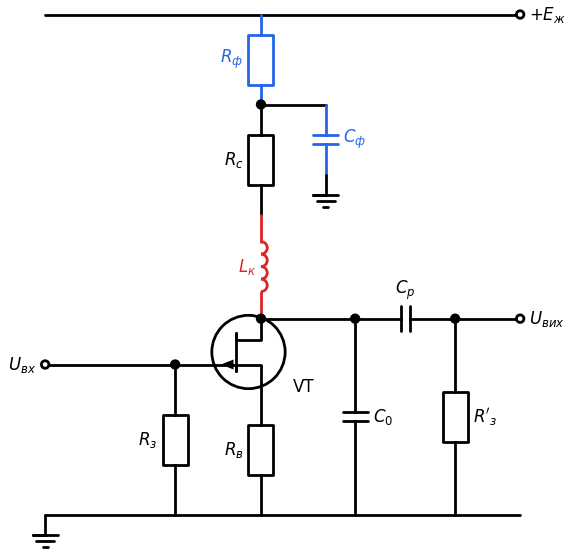

In [8]:
# Каскад СВ зі стоковою корекцією: ВЧ — котушка L_к, НЧ — фільтр R_ф C_ф
if SCHEMDRAW_AVAILABLE:
    with schemdraw.Drawing(fontsize=12, unit=2) as d:
        W = lambda p1, p2: elm.Line().at(p1).to(p2)
        d += W((0, 10), (9.5, 10)); d += elm.Dot(open=True).at((9.5, 10)).label('$+E_ж$', loc='right')
        d += W((0, 0), (9.5, 0)); d += elm.Ground().at((0, 0))
        d += elm.Dot(open=True).at((0, 3.0)).label('$U_{вх}$', loc='left')
        d += W((0, 3.0), (3.4, 3.0)); d += elm.Dot().at((2.6, 3.0))
        d += elm.Resistor().at((2.6, 3.0)).to((2.6, 0)).label('$R_з$', loc='top')
        d += (q := elm.JFetN(circle=True).theta(0).reverse().at((3.4, 3.0)).anchor('gate'))
        d += elm.Label().at((q.source[0] + 0.75, 2.65)).label('VT')
        d += elm.Resistor().at((q.source[0], q.source[1])).to((q.source[0], 0)).label('$R_в$', loc='top')
        x = q.drain[0]
        d += elm.Resistor().at((x, 10)).to((x, 8.2)).label('$R_ф$', loc='top').color('#2563eb')
        d += elm.Dot().at((x, 8.2)); d += W((x, 8.2), (x + 1.3, 8.2))
        d += elm.Capacitor().at((x + 1.3, 8.2)).to((x + 1.3, 6.8)).label('$C_ф$', loc='bottom').color('#2563eb')
        d += elm.Ground().at((x + 1.3, 6.8))
        d += elm.Resistor().at((x, 8.2)).to((x, 6.0)).label('$R_с$', loc='top')
        d += elm.Inductor().at((x, 6.0)).to(q.drain).label('$L_к$', loc='top').color('#dc2626')
        d += elm.Dot().at(q.drain)
        d += W(q.drain, (6.2, q.drain[1])); d += elm.Dot().at((6.2, q.drain[1]))
        d += elm.Capacitor().at((6.2, q.drain[1])).to((6.2, 0)).label('$C_0$', loc='bottom')
        d += elm.Capacitor().at((6.2, q.drain[1])).to((8.2, q.drain[1])).label('$C_р$')
        d += elm.Dot().at((8.2, q.drain[1])); d += W((8.2, q.drain[1]), (9.5, q.drain[1])); d += elm.Dot(open=True).at((9.5, q.drain[1])).label('$U_{вих}$', loc='right')
        d += elm.Resistor().at((8.2, q.drain[1])).to((8.2, 0)).label("$R'_з$", loc='bottom')

---
### 🔬 Інтерактивно: індуктивна ВЧ-корекція: АЧХ і перехідна характеристика (PySpice) <a class="anchor" id="drain-corr-interactive"></a>

<div style="background-color: #f5f3ff; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #7c3aed; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

Каскад СВ ($R_с = 2$ кОм, $C_0 = 100$ пФ) зі стоковою котушкою $L_к = mR_с^2C_0$. Змінюйте параметр $m$: при $m \approx 0{,}41$ АЧХ максимально плоска і смуга розширюється в ≈1,7 раза, при $m > 0{,}5$ з'являються підйом АЧХ і викид на фронті імпульсу.

</div>

In [9]:
# Стокова індуктивна корекція (PySpice): АЧХ і реакція на імпульс
def drain_corr(m=0.414):
    R, C0 = 2e3, 100e-12
    def build(mm, pulse=False):
        c = Circuit('shunt peaking')
        c.model('JN', 'NJF', VTO=-2.0, BETA=1e-3, LAMBDA=5e-3, CGS=4e-12, CGD=2e-12)   # ПТ: I_с.поч = 4 мА, U_відс = −2 В
        c.V('dd', 'vdd', c.gnd, 15)
        if pulse:
            c.PulseVoltageSource('in', 'g', c.gnd, initial_value=0, pulsed_value=-0.05, delay_time=20e-9,
                                 rise_time=1e-9, fall_time=1e-9, pulse_width=2e-6, period=4e-6)
        else:
            c.SinusoidalVoltageSource('in', 'g', c.gnd, amplitude=1e-3, ac_magnitude=1)
        c.JFET(1, 'out', 'g', 's', model='JN'); c.R('s', 's', c.gnd, 680); c.C('s', 's', c.gnd, 1e-3)
        c.R('d', 'vdd', 'x', R); c.C('0', 'out', c.gnd, C0)
        if mm > 0:
            c.L('k', 'x', 'out', mm * R * R * C0)
        else:
            c.R('k', 'x', 'out', 1e-3)
        return c
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    out = []
    for mm, col, ls in ((0, 'k', '--'), (m, '#F44336', '-')):
        f, v = ac(build(mm), 1e4, 1e8, 60)
        g = np.abs(v['out']); g0 = g[0]; fv = f[np.argmax(g < g0 / np.sqrt(2))]
        a1.semilogx(f, db(g / g0), color=col, ls=ls, label=f'm = {mm:.2f}: fв = {fv/1e6:.2f} МГц')
        t, vt = tran(build(mm, True), 2e-9, 1.2e-6)
        y = vt['out'] - vt['out'][0]
        a2.plot(t * 1e6, y / y[np.argmin(abs(t - 1.0e-6))], color=col, ls=ls, label=f'm = {mm:.2f}')
        out.append(fv)
    a1.axhline(-3, color='#FF9800', ls=':'); a1.set_ylim(-15, 6); a1.set_xlabel('Частота, Гц'); a1.set_ylabel('K/K₀, дБ'); a1.legend(); a1.set_title('АЧХ')
    a2.set_xlim(0, 1.2); a2.set_xlabel('t, мкс'); a2.set_ylabel('нормована вихідна напруга'); a2.legend(); a2.set_title('Реакція на стрибок')
    plt.tight_layout(); plt.show()
    print(f'L_к = m·R²·C0 = {m*R*R*C0*1e6:.1f} мкГн;  розширення смуги: {out[1]/out[0]:.2f} раза')

interact(drain_corr, m=widgets.FloatSlider(min=0, max=1.0, step=0.01, value=0.414, description='m'));

interactive(children=(FloatSlider(value=0.414, description='m', max=1.0, step=0.01), Output()), _dom_classes=(…

### ⚠️ Типова помилка

<div style="background-color: #fef2f2; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #dc2626; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

**Корекція не збільшує «площу підсилення» безкоштовно.** Витокова корекція розширює смугу ціною пропорційного зменшення підсилення; індуктивна — перерозподіляє енергію в контурі $L_кC_0$ і дає обмежене розширення (до ~1,7 раза для простої схеми). Перекорекція ($m$ або $C_к$ завеликі) спричиняє підйом АЧХ і викиди на фронтах імпульсів — для імпульсних підсилювачів це неприйнятно.

</div>

---
### ⚡ Практичне застосування: корекція АЧХ у реальних пристроях

<div style="background-color: #fffbeb; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #f59e0b; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Пристрій | Метод корекції |
|---|---|
| Відеопідсилювач телевізора, драйвер кінескопа / дисплея | стокова (колекторна) індуктивна корекція, емітерна RC-корекція |
| Широкосмуговий підсилювач осцилографа | комбінація емітерної і індуктивної корекції, каскодні каскади |
| Підсилювач фотоприймача (TIA) | корекція ємністю в колі ЗЗ (тема 8) |
| Інтегральні широкосмугові підсилювачі (CML-буфери) | «активна індуктивність», shunt peaking на кристалі |
| Підсилювач з розділювальними конденсаторами | НЧ-корекція фільтром $R_фC_ф$ у колі живлення |

</div>

---
### ✅ Питання для самоперевірки: каскади СС, СБ, СЗ і корекція АЧХ

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 1.</b> Чому витоковий повторювач має більший вихідний опір, ніж емітерний?</summary>

> **Відповідь:** Вихідний опір повторювача ≈ $1/g_m$, а крутизна ПТ на порядок менша за крутизну БТ $I_к/\varphi_т$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 2.</b> Що таке вольтодобавка у повторювачі?</summary>

> **Відповідь:** Підключення нижнього кінця резистора зміщення затвора (бази) до виходу/відводу: змінна напруга на резисторі зменшується до $u_{вх}(1-K)$, і його ефективний опір зростає в $1/(1-K)$ разів.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 3.</b> Чому каскад СБ має ширшу смугу, ніж СЕ?</summary>

> **Відповідь:** Немає ефекту Міллера: ємність колекторного переходу не з'єднує вихід із входом; гранична частота визначається $f_\alpha \approx f_т$, а не $f_\beta = f_т/\beta$.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 4.</b> Як вибрати ємність витокової корекції?</summary>

> **Відповідь:** З умови $R_вC_к = R_сC_0$: нуль кола $R_вC_к$ компенсує полюс навантаження; смуга зростає в $1 + SR_в$ разів.

</details>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;"><b>Питання 5.</b> Що таке параметр $m$ індуктивної корекції?</summary>

> **Відповідь:** $m = L_к/(R_с^2C_0)$; при $m \approx 0{,}41$ АЧХ максимально плоска, смуга ≈1,7 раза ширша.

</details>

---
### 📝 Задачі для самостійного розв'язання: каскади СС, СБ, СЗ і корекція


<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 1.** Витоковий повторювач: $S = 3$ мА/В, $R_в = 4{,}7$ кОм, $R_н = 2$ кОм. Знайдіть $K_u$ і $R_{вих}$.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $R\'_в = 1{,}4$ кОм; $SR\'_в = 4{,}2$; $K_u = 4{,}2/5{,}2 = 0{,}81$; $R_{вих} = 4{,}7\text{ к}\parallel333 \approx 311$ Ом.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 2.** Каскад СБ: $I_{е0} = 2$ мА, $R_к = 3{,}3$ кОм, $R_н = 10$ кОм. Знайдіть $R_{вх}$ і $K_u$; яке наскрізне підсилення від джерела з $R_c = 50$ Ом?

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $r_е = 13$ Ом, $R_{вх} \approx 13$ Ом; $g_m = 77$ мА/В, $K_u = 77\cdot2{,}48 \approx 191$; наскрізне: $191\cdot13/63 \approx 39$.

</details>

<div style="background-color: #fff1f2; padding: 12px 18px; border-radius: 10px; border-left: 4px solid #e11d48; box-shadow: 0 1px 3px rgba(0,0,0,0.08); margin: 10px 0;">

**Задача 3.** Каскад СВ: $R_с = 1{,}5$ кОм, $C_0 = 20$ пФ. Знайдіть некориговану $f_в$ і індуктивність для максимально плоскої АЧХ.

</div>

<details style="margin: 10px 0; padding: 10px 14px; background: #ecfdf5; border-radius: 8px; border-left: 3px solid #0d9488;">
<summary style="cursor: pointer; font-weight: 600; color: #0f766e;">Відповідь і розв'язання</summary>

> $f_{в0} = 1/(2\pi R_сC_0) = 5{,}3$ МГц; $L_к = 0{,}414\cdot1500^2\cdot20\cdot10^{-12} = 18{,}6$ мкГн; $f_в \approx 9{,}1$ МГц.

</details>

---

### 📌 Підсумок теми <a class="anchor" id="topic-summary"></a>

<div style="background-color: #f0fdf4; padding: 16px 18px; border-radius: 10px; border-left: 4px solid #16a34a; box-shadow: 0 1px 3px rgba(0,0,0,0.08);">

| Каскад / метод | Основні співвідношення |
|---|---|
| СС (витоковий повторювач) | $K_u = \dfrac{SR'_в}{1+SR'_в}$, $R_{вих} \approx 1/S$, $R_{вх} = R_з$ (з вольтодобавкою — $R_з/(1-K)$) |
| СБ | $K_u = g_m(R_к\parallel R_н)$, $K_i = \alpha$, $R_{вх} \approx r_е$, $R_{вих} \approx R_к$, немає ефекту Міллера |
| СЗ | $K_u = S(R_с\parallel R_н)$, $R_{вх} \approx 1/S$ |
| Витокова ВЧ-корекція | $R_вC_к = R_сC_0$; $f_в$ зростає в $1+SR_в$ разів, $K$ зменшується в стільки ж |
| Стокова ВЧ-корекція | $L_к = mR_с^2C_0$, $m = 0{,}41$ — максимально плоска АЧХ, $f_в \times 1{,}72$ |
| Стокова НЧ-корекція | $R_сC_ф = R_зC_р$ |

**Головні висновки.** Повторювачі (СК, СС) — буфери з великим $R_{вх}$ і малим $R_{вих}$; каскади СБ і СЗ — «повторювачі струму» з широкою смугою, основа каскодних схем. Корекція АЧХ розширює смугу пропускання або частотно-залежним НЗЗ (з боку витоку/емітера — ціною підсилення), або резонансним підйомом у колі навантаження (з боку стоку/колектора — без втрати підсилення).

</div>

---

## 📚 Рекомендована література та ресурси <a class="anchor" id="references"></a>

**Основна література**

1. Гусев В. Г., Гусев Ю. М. Електроніка і мікропроцесорна техніка. — К.: Вища школа (укр. пер.).
2. Опадчий Ю. Ф., Глудкин О. П., Гуров А. И. Аналоговая и цифровая электроника. — М.: Горячая линия – Телеком, 2000.
3. Титце У., Шенк К. Полупроводниковая схемотехника. — 12-е изд. — М.: ДМК Пресс, 2008.
4. Хоровиц П., Хилл У. Искусство схемотехники. — М.: Мир / Horowitz P., Hill W. The Art of Electronics. — 3rd ed. — Cambridge University Press, 2015.
5. Sedra A. S., Smith K. C. Microelectronic Circuits. — 8th ed. — Oxford University Press, 2020.

**Додаткова література**

6. Лурье О. Б. Усилители видеочастоты. — М.: Сов. радио, 1961.
7. Lee T. H. The Design of CMOS Radio-Frequency Integrated Circuits. — 2nd ed. — Cambridge University Press, 2004 (розділ про shunt peaking).

**Програмні інструменти, що використовуються в конспекті**

- [PySpice](https://pyspice.fabrice-salvaire.fr/) + [ngspice](https://ngspice.sourceforge.io/) — схемотехнічне моделювання
- [SchemDraw](https://schemdraw.readthedocs.io/) — побудова електричних схем
- [SymPy](https://docs.sympy.org/) — символьні обчислення
- [NumPy](https://numpy.org/doc/) / [SciPy](https://docs.scipy.org/doc/scipy/) / [Matplotlib](https://matplotlib.org/) — чисельні розрахунки та графіки

---

<p style="text-align: center;">⬅️ [Тема 3. Каскади зі спільним емітером, спільним витоком і спільним колектором](Тема_03_Каскади_СЕ_СВ_СК.ipynb) &nbsp;|&nbsp; [Тема 5. Складові повторювачі, підсилювальні двійки, каскодні схеми](Тема_05_Складові_повторювачі_двійки_каскод.ipynb) ➡️</p>

*Конспект підготовлено: Пахалюк Богдан Петрович, НУ "Чернігівська політехніка"*